In [1]:
import gc
import joblib

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

import optuna
import optuna.visualization as vis
from optuna.integration import XGBoostPruningCallback

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, make_scorer, r2_score, root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler

import xgboost as xgb

from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import Ridge



<h2>Read-in Data</h2>

In [3]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32'
}

In [4]:
campd_wy = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_wy["Date"] = pd.to_datetime(campd_wy["Date"])
campd_wy["datetime"] = pd.to_datetime(campd_wy["datetime"])

C:\Users\marce\AppData\Local\Temp\ipykernel_23128\3537547202.py:1: DtypeWarning: Columns (52) have mixed types. Specify dtype option on import or set low_memory=False.
  campd_wy = pd.read_csv("WY/Hourly/Concatted File/wy_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)


<h2>Preprocessing Methods</h2>

In [5]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # add the previous year temporarily to get lags for the first year
    df = pd.concat([df, previous_year_df])

    df = df.set_index("datetime")

    df = df.sort_index()
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # apply the lag feature function to each group
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime({
    'year': df["Date"].dt.year,
    'month': df["Date"].dt.month,
    'day': df["Date"].dt.day,
    'hour': df["Hour"]
    })

    return df


In [6]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # Split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # Concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_wy, wy_code_cols = preprocess_program_codes(campd_wy)
# wy_code_cols

<h2>Model-independent Preprocessing</h2>

- create time-lags
- manually OHE program codes
- (no downsampling since size is not significant for these datasets)
- remove rows where CO2 was not fully measured

In [ ]:
# read in previous year to get according lags
campd_wy_2018 = pd.read_csv("WY/Hourly/Before 2019/emissions-hourly-2018-wy.csv", dtype=campd_type_dict, parse_dates=["Date"])
campd_wy_2018 = campd_wy_2018[["Facility ID", "Unit ID", "Date", "Hour", "CO2 Mass (short tons)"]]
campd_wy_2018["datetime"] = pd.to_datetime({
    'year': campd_wy_2018["Date"].dt.year,
    'month': campd_wy_2018["Date"].dt.month,
    'day': campd_wy_2018["Date"].dt.day,
    'hour': campd_wy_2018["Hour"]
    })
campd_wy_2018["CO2 Mass (short tons)"] = campd_wy_2018["CO2 Mass (short tons)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_wy, campd_wy_2018, "CO2 Mass (short tons)")

In [9]:
campd_df.to_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/wy_2019_2024_complete_cleaned_Full_with_CO2_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/wy_2019_2024_complete_cleaned_Full_with_CO2_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [10]:
# manually one-hot encode program codes
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [11]:
campd_df.to_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/wy_2019_2024_complete_cleaned_Full_manually_encoded.csv", index=False)

In [ ]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/wy_2019_2024_complete_cleaned_Full_manually_encoded.csv", dtype=campd_type_dict)

In [12]:
campd_df["CO2 Mass Measure Indicator"].value_counts()

CO2 Mass Measure Indicator
Measured                   983249
Nothing                    321772
Measured and Substitute      9733
Substitute                    446
Name: count, dtype: Int64

In [13]:
campd_df = campd_df[(campd_df["CO2 Mass Measure Indicator"] == "Measured") | (campd_df["CO2 Mass Measure Indicator"] == "Nothing")]
campd_df["CO2 Mass Measure Indicator"].value_counts()

CO2 Mass Measure Indicator
Measured    983249
Nothing     321772
Name: count, dtype: Int64

In [14]:
campd_df.to_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/wy_2019_2024_complete_cleaned_Full_manually_only_measured.csv", index=False)

<h2>Regression Models</h2>

<h3>Linear Regression</h3>

In [ ]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/wy_2019_2024_complete_cleaned_Full_manually_only_measured.csv", dtype=campd_type_dict)

In [87]:
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)']

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

In [ ]:
navals = campd_df[num_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# remove nan cols with excessive number of nan vals otherwise removing respective nan rows

hourly_ramping_factor     0.000482
Summer Capacity (MW)     67.412830
Winter Capacity (MW)     67.412830
Minimum Load (MW)        67.412830
Temperature (F)           4.328061
dtype: float64

In [ ]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

In [92]:
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                # 'Summer Capacity (MW)',
                # 'Winter Capacity (MW)', 
                # 'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'] #+ lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

R^2 Score: 0.9688
Mean Squared Error (MSE): 823.6654
Root Mean Squared Error (RMSE): 28.6996
Normalized RMSE (by std): 0.1766


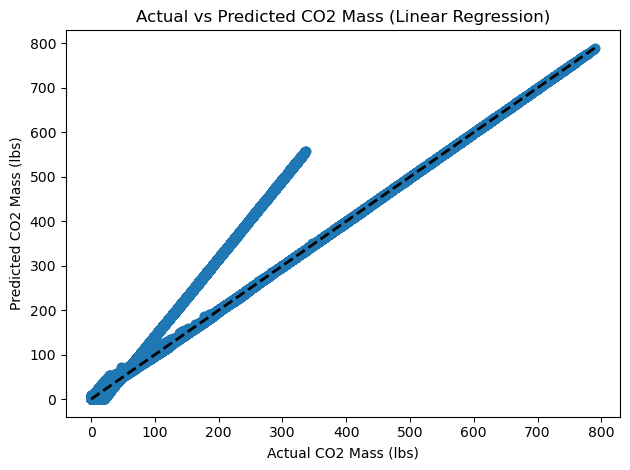

In [ ]:
# default model (no lags, no unmeasured, with temps)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

# Predict on test set
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

# Plot actual vs predicted
plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()


R^2 Score: 1.0000
Mean Squared Error (MSE): 0.3779
Root Mean Squared Error (RMSE): 0.6147
Normalized RMSE (by std): 0.0036


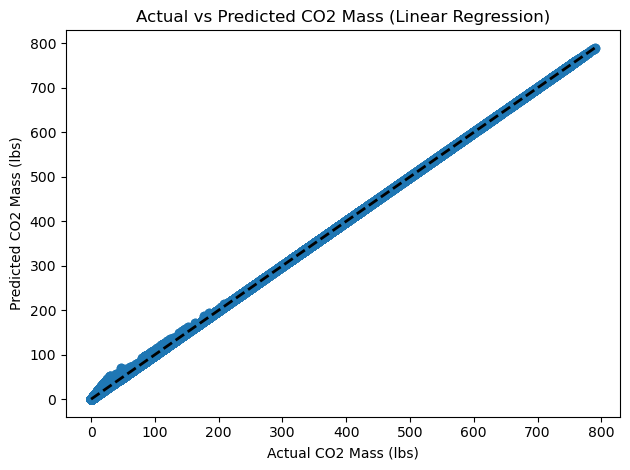

In [95]:
# default model (no lags, no unmeasured, with temps)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train_filtered, y_train_filtered)

# Predict on test set
y_pred = lr_model.predict(X_test_filtered)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

# Evaluate performance
print(f"R^2 Score: {r2_score(y_test_filtered, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test_filtered, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test_filtered, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test_filtered, y_pred)) / np.std(y_test_filtered):.4f}")

# Plot actual vs predicted
plt.scatter(y_test_filtered, y_pred)
plt.xlabel("Actual CO2 Mass (lbs)")
plt.ylabel("Predicted CO2 Mass (lbs)")
plt.title("Actual vs Predicted CO2 Mass (Linear Regression)")
plt.plot([min(y_test_filtered.min(), y_pred.min()), max(y_test_filtered.max(), y_pred.max())], [min(y_test_filtered.min(), y_pred.min()), max(y_test_filtered.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()


<h3>XGBoost</h3>

<h5>Preprocessing Methods</h5>

<h5>Full Model Train and Test</h5>

<h6>Preprocessing</h6>

In [ ]:
campd_df = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/wy_2019_2024_complete_cleaned_Full_manually_only_measured.csv", dtype=campd_type_dict)

In [76]:
# features
df_code_cols = ['ARP', 'MATS']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ] #+ lag_cols

unencoded_cat_features = ['Month', 'Hour', 'Day',
                    'Source Category', 
                    'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_code_cols) # for passthrough of the manually one-hot encoded cols

target_variable = "CO2 Mass (short tons)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["CO2 Mass (short tons)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (CO2 Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_factor',
                                  'Summer Capacity (MW)',
                                  'Winter Capacity (MW)', 'Minimum Load (MW)',
                                  'Year', 'Temperature (F)']),
                                ('encoded', 'passthrough', ['ARP', 'MATS'])])

In [ ]:
X_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/X_train.csv", index=False)
X_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/X_test.csv", index=False)
y_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/y_train.csv", index=False)
y_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/y_test.csv", index=False)

In [ ]:
X_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/X_train.csv", dtype=campd_type_dict)
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/X_test.csv", dtype=campd_type_dict)

In [ ]:
y_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/y_train.csv")
y_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/y_test.csv")

In [77]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
X_train.to_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/X_train_processed.csv", index=False)
X_test.to_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/X_test_processed.csv", index=False)

In [ ]:
X_train = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/X_train_processed.csv", dtype=campd_type_dict)
X_test = pd.read_csv("WY/Hourly/Concatted File/Modeling/XGB/CO2/X_test_processed.csv", dtype=campd_type_dict)

In [78]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [ ]:
dtrain.save_binary("WY/Hourly/Concatted File/Modeling/XGB/CO2/dtrain_wy_full_2019_2023.buffer")
dtest.save_binary("WY/Hourly/Concatted File/Modeling/XGB/CO2/dtest_wy_full_2024.buffer")

In [ ]:
dtrain = xgb.DMatrix("WY/Hourly/Concatted File/Modeling/XGB/CO2/dtrain_wy_full_2019_2023.buffer")
dtest = xgb.DMatrix("WY/Hourly/Concatted File/Modeling/XGB/CO2/dtest_wy_full_2024.buffer")

In [ ]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse'
}

R^2 Score: 0.9721
Mean Squared Error (MSE): 748.0828
Root Mean Squared Error (RMSE): 27.3511
Normalized RMSE (by std): 0.1671


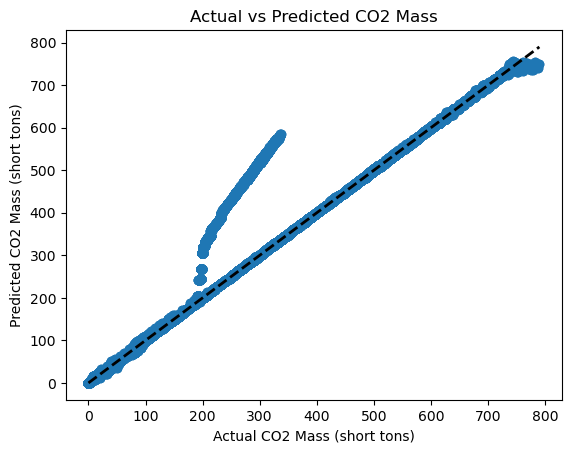

In [39]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("WY/Hourly/Concatted File/Modeling/XGB/CO2/Trained Models/xgb_default_model_wy_no_lags_no_unmeasured.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted CO2 Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

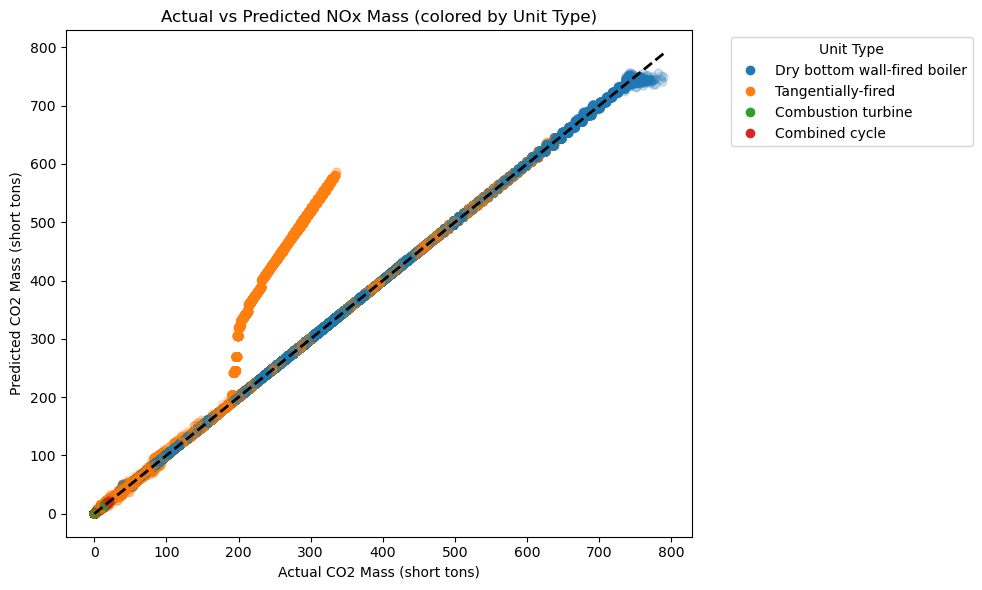

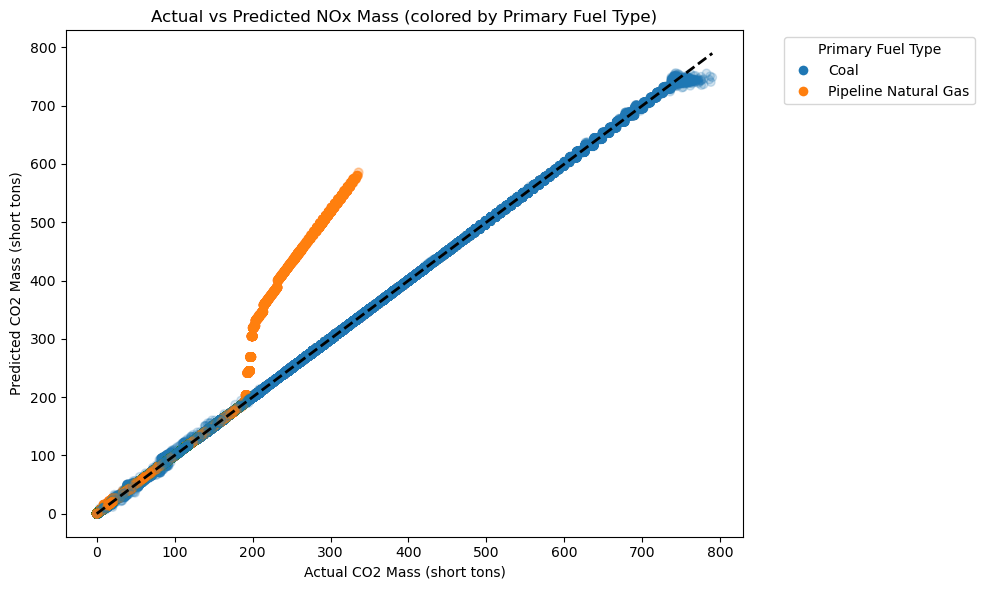

In [42]:
train_mask = (campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())

unit_types_test = campd_df.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types))  
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

#####################################################

train_mask = (campd_df["Year"] < 2024) & (campd_df["CO2 Mass (short tons)"].notna())
test_mask = (campd_df["Year"] == 2024) & (campd_df["CO2 Mass (short tons)"].notna())

fuel_types_test = campd_df.loc[test_mask, "Primary Fuel Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_fuel_types = fuel_types_test.unique()
palette = sns.color_palette("tab10", len(unique_fuel_types))  
color_mapping = dict(zip(unique_fuel_types, palette))
colors = fuel_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.1)
plt.xlabel("Actual CO2 Mass (short tons)")
plt.ylabel("Predicted CO2 Mass (short tons)")
plt.title("Actual vs Predicted NOx Mass (colored by Primary Fuel Type)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_fuel_types]
plt.legend(handles=handles, title="Primary Fuel Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


